# Paso 5. Análisis de Componentes Principales (PCA) y Paso 6. Consolidación

## Preparación
Se realiza la inserción de la ruta para utilizar archivos del proyecto, y se carga el dataset normalizado.

In [1]:
import polars as pl
import sys
from pathlib import Path

ROOT = Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from config.rutas import RUTA_DATA_PROCESSED
lectura_normalizada = pl.read_csv(RUTA_DATA_PROCESSED / "normalized_consumption.csv", try_parse_dates=True)

## Descarte de variables redundantes (Paso 4)
Se verifica qué pares superan el umbral de 0.85 y se descarta `global_intensity`.

In [2]:
import src.measurements.correlations as correlate

matriz = correlate.matriz_correlaciones(correlate.obtener_numericas(lectura_normalizada))
print(correlate.pares_redundantes(matriz, umbral=0.85))

df_reducido = correlate.descartar_redundantes(lectura_normalizada)
print(df_reducido.columns)

Fontconfig error: "/home/f1x1/.config/fontconfig/fonts.conf", line 42: no element found


shape: (1, 3)
┌─────────────────────┬──────────────────┬──────────┐
│ variable_1          ┆ variable_2       ┆ pearson  │
│ ---                 ┆ ---              ┆ ---      │
│ str                 ┆ str              ┆ f64      │
╞═════════════════════╪══════════════════╪══════════╡
│ global_active_power ┆ global_intensity ┆ 0.998887 │
└─────────────────────┴──────────────────┴──────────┘
['datetime', 'global_active_power', 'global_reactive_power', 'voltage', 'sub_metering_1', 'sub_metering_2', 'sub_metering_3']


## 1. Verificación de estandarización
Se revisa sobre la porción de entrenamiento (primer 80%), que es con la que se calcularon los parámetros del z-score.

In [3]:
import src.reduction.pca as pca_mod

pl.Config.set_tbl_cols(-1)
pl.Config.set_tbl_width_chars(200)
print(pca_mod.verificar_estandarizacion(df_reducido))

shape: (6, 3)
┌───────────────────────┬─────────────┬────────────┐
│ variable              ┆ media       ┆ desviacion │
│ ---                   ┆ ---         ┆ ---        │
│ str                   ┆ f64         ┆ f64        │
╞═══════════════════════╪═════════════╪════════════╡
│ global_active_power   ┆ -1.0956e-17 ┆ 1.0        │
│ global_reactive_power ┆ -2.6405e-16 ┆ 1.0        │
│ voltage               ┆ -1.1570e-14 ┆ 1.0        │
│ sub_metering_1        ┆ 2.2735e-17  ┆ 1.0        │
│ sub_metering_2        ┆ -3.9717e-18 ┆ 1.0        │
│ sub_metering_3        ┆ -3.9443e-17 ┆ 1.0        │
└───────────────────────┴─────────────┴────────────┘


## 2. Ajuste del PCA y varianza explicada

In [4]:
pca = pca_mod.ajustar_pca(df_reducido)
print(pca_mod.tabla_varianza(pca))

shape: (6, 4)
┌────────────┬──────────────┬────────────────────┬────────────────────┐
│ componente ┆ valor_propio ┆ varianza_explicada ┆ varianza_acumulada │
│ ---        ┆ ---          ┆ ---                ┆ ---                │
│ str        ┆ f64          ┆ f64                ┆ f64                │
╞════════════╪══════════════╪════════════════════╪════════════════════╡
│ PC1        ┆ 2.310547     ┆ 0.385091           ┆ 0.385091           │
│ PC2        ┆ 0.986231     ┆ 0.164372           ┆ 0.549463           │
│ PC3        ┆ 0.933574     ┆ 0.155596           ┆ 0.705059           │
│ PC4        ┆ 0.834077     ┆ 0.139013           ┆ 0.844072           │
│ PC5        ┆ 0.771261     ┆ 0.128544           ┆ 0.972615           │
│ PC6        ┆ 0.164309     ┆ 0.027385           ┆ 1.0                │
└────────────┴──────────────┴────────────────────┴────────────────────┘


## 3. Scree plot y selección de componentes

Componentes retenidos: 4


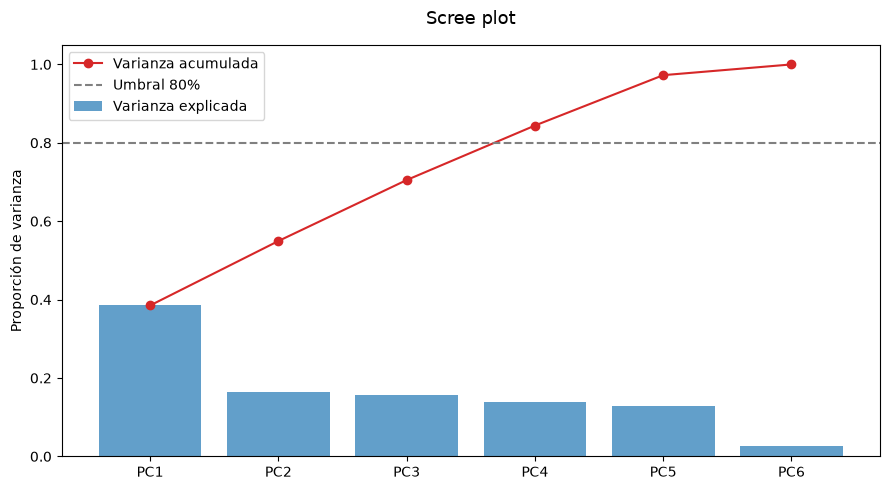

In [5]:
n_componentes = pca_mod.seleccionar_componentes(pca, umbral=0.8)
print(f"Componentes retenidos: {n_componentes}")
pca_mod.graficar_scree(pca, umbral=0.8)

## 4. Interpretación de loadings

shape: (6, 5)
┌───────────────────────┬──────────┬───────────┬───────────┬───────────┐
│ variable              ┆ PC1      ┆ PC2       ┆ PC3       ┆ PC4       │
│ ---                   ┆ ---      ┆ ---       ┆ ---       ┆ ---       │
│ str                   ┆ f64      ┆ f64       ┆ f64       ┆ f64       │
╞═══════════════════════╪══════════╪═══════════╪═══════════╪═══════════╡
│ global_active_power   ┆ 0.60958  ┆ -0.073215 ┆ -0.034785 ┆ -0.049531 │
│ global_reactive_power ┆ 0.248732 ┆ 0.678471  ┆ 0.278108  ┆ 0.627519  │
│ voltage               ┆ -0.38181 ┆ 0.163508  ┆ 0.05439   ┆ 0.023771  │
│ sub_metering_1        ┆ 0.356484 ┆ -0.026959 ┆ 0.728463  ┆ -0.459719 │
│ sub_metering_2        ┆ 0.324076 ┆ 0.50791   ┆ -0.579459 ┆ -0.444933 │
│ sub_metering_3        ┆ 0.434349 ┆ -0.498881 ┆ -0.228158 ┆ 0.440335  │
└───────────────────────┴──────────┴───────────┴───────────┴───────────┘


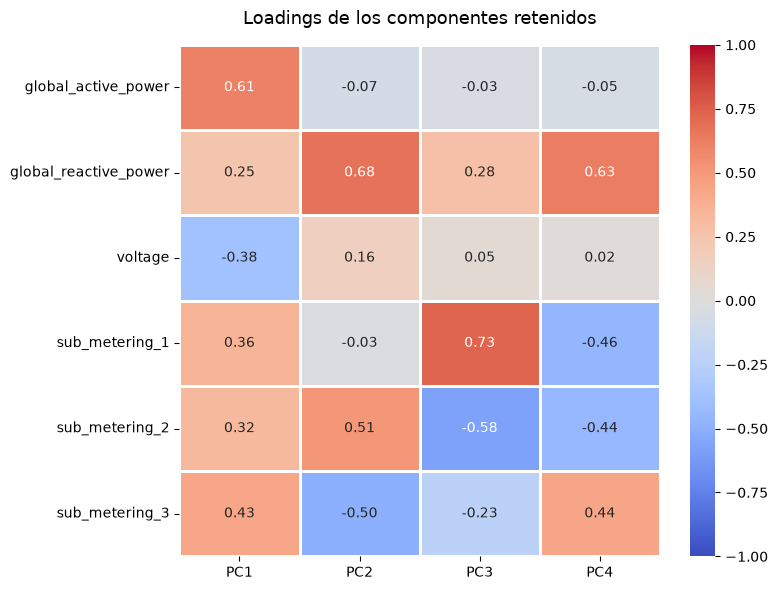

In [6]:
variables = pca_mod.columnas_numericas(df_reducido)
loadings = pca_mod.tabla_loadings(pca, variables, n_componentes)
print(loadings)
pca_mod.graficar_loadings(loadings)

## 5. Proyección en 2D

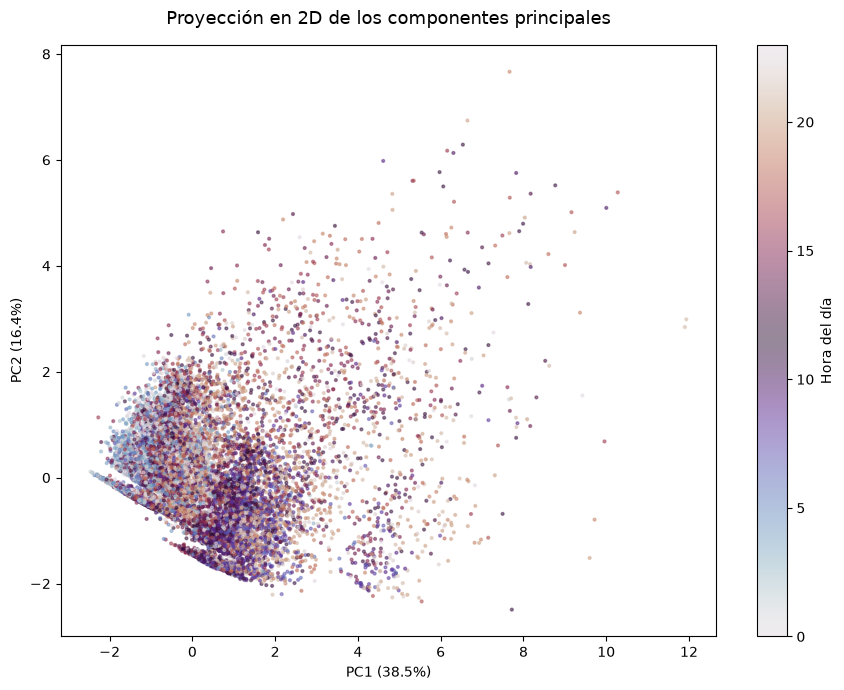

In [7]:
pca_mod.graficar_proyeccion_2d(df_reducido, pca)

## 6. Consolidación del dataset preparado
Se guarda en `data/data-processed/prepared_consumption.csv` el dataset normalizado, sin variables redundantes y con los componentes retenidos.

In [8]:
import src.cleaning.consolidation as cns

cns.consolidacion_de_normalizado()

preparado = pl.read_csv(RUTA_DATA_PROCESSED / "prepared_consumption.csv", try_parse_dates=True)
print(preparado.shape)
print(preparado.head())

(2075259, 11)
shape: (5, 11)
┌─────────────────────┬─────────────────────┬───────────────────────┬───────────┬────────────────┬────────────────┬────────────────┬──────────┬──────────┬──────────┬──────────┐
│ datetime            ┆ global_active_power ┆ global_reactive_power ┆ voltage   ┆ sub_metering_1 ┆ sub_metering_2 ┆ sub_metering_3 ┆ pc1      ┆ pc2      ┆ pc3      ┆ pc4      │
│ ---                 ┆ ---                 ┆ ---                   ┆ ---       ┆ ---            ┆ ---            ┆ ---            ┆ ---      ┆ ---      ┆ ---      ┆ ---      │
│ datetime[μs]        ┆ f64                 ┆ f64                   ┆ f64       ┆ f64            ┆ f64            ┆ f64            ┆ f64      ┆ f64      ┆ f64      ┆ f64      │
╞═════════════════════╪═════════════════════╪═══════════════════════╪═══════════╪════════════════╪════════════════╪════════════════╪══════════╪══════════╪══════════╪══════════╡
│ 2006-12-16 17:24:00 ┆ 2.84479             ┆ 2.645453              ┆ -1.756826 ┆ -0.1